#Benchmark para a implementação da aritimética Takum
###- Multiplicação de matriz por vetor
###- Distribuição de erro relativo acumulado (Float128)
###- Redução na complexidade de instruções e do registro de controle e status  (CSRs).

###Importação das bibliotecas e configuração inicial

In [10]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TIPOS = ["T8", "T16", "T32", "F32", "F64"]
COLORS = {
    "T8": "#1f77b4",
    "T16": "#2ca02c",
    "T32": "#d62728",
    "F32": "#9467bd",
    "F64": "#8c564b",
}
MARKERS = {"T8": "o", "T16": "s", "T32": "^", "F32": "D", "F64": "v"}

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 160,
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

FIG_DIR = Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

###Importação e leitura dos arquivos de dados (.csv)

In [11]:
def load_results(path: Path) -> pd.DataFrame:
    if not path.exists():
        sys.exit(f"[erro] arquivo não encontrado: {path}")

    df = pd.read_csv(path)
    required = {
        "size", "nnz", "tipo", "repeat", "time_s",
        "csr_writes_est", "inst_retired", "elements", "configs",
        "err_mean", "err_rms", "err_max", "err_p95", "err_p99", "out0",
    }
    missing = required - set(df.columns)
    if missing:
        sys.exit(f"[erro] colunas ausentes em {path}: {sorted(missing)}")

    df["tipo"] = df["tipo"].astype(str).str.strip().str.upper()

    bad = df[(df["err_mean"] > df["err_max"] * (1 + 1e-9)) &
             np.isfinite(df["err_mean"]) & np.isfinite(df["err_max"])]
    if not bad.empty:
        df.loc[~np.isfinite(df["err_mean"]), "err_mean"] = np.nan
        df.loc[~np.isfinite(df["err_max"]),  "err_max"]  = np.nan
        df.loc[~np.isfinite(df["err_p95"]),  "err_p95"]  = np.nan
        df.loc[~np.isfinite(df["err_p99"]),  "err_p99"]  = np.nan

    return df

def load_hist(path: Path) -> pd.DataFrame | None:
    if not path.exists():
        return None
    return pd.read_csv(path)

def _save_table(df: pd.DataFrame, stem: Path) -> None:
    df.to_csv(stem.with_suffix(".csv"))
    md = df.copy()
    for c in md.columns:
        if np.issubdtype(md[c].dtype, np.floating):
            md[c] = md[c].map(lambda v: f"{v:.4e}" if np.isfinite(v) else "—")
    md.to_markdown(stem.with_suffix(".md"))
    try:
        df.to_latex(stem.with_suffix(".tex"), float_format="%.3e", escape=True)
    except Exception:
        pass

def table_summary(df: pd.DataFrame, out_dir: Path) -> pd.DataFrame:
    g = df.groupby("tipo", sort=False)
    agg = pd.DataFrame({
        "time_ms_mean":  g["time_s"].mean() * 1e3,
        "time_ms_std":   g["time_s"].std() * 1e3,
        "err_mean":      g["err_mean"].mean(),
        "err_max_global": g["err_max"].max(),
        "err_p95":       g["err_p95"].mean(),
        "err_p99":       g["err_p99"].mean(),
        "inst_retired":  g["inst_retired"].sum(),
        "elements":      g["elements"].sum(),
        "csr_writes":    g["csr_writes_est"].sum(),
        "samples":       g["err_mean"].count(),
    }).reindex(TIPOS).dropna(how="all")
    _save_table(agg, out_dir / "tbl_summary")
    return agg

def table_by_size(df: pd.DataFrame, out_dir: Path) -> pd.DataFrame:
    pivot_err = df.pivot_table(
        index="size", columns="tipo",
        values="err_mean", aggfunc="mean",
    ).reindex(columns=TIPOS)
    pivot_t = df.pivot_table(
        index="size", columns="tipo",
        values="time_s", aggfunc="mean",
    ).reindex(columns=TIPOS) * 1e3

    err = pivot_err.add_suffix("_err_mean")
    tim = pivot_t.add_suffix("_time_ms")
    out = pd.concat([err, tim], axis=1)
    _save_table(out, out_dir / "tbl_by_size")
    return out

df = load_results(Path("benchmark_results.csv"))
table_summary(df, FIG_DIR)
table_by_size(df, FIG_DIR)

tipo,T8_err_mean,T16_err_mean,T32_err_mean,F32_err_mean,F64_err_mean,T8_time_ms,T16_time_ms,T32_time_ms,F32_time_ms,F64_time_ms
size,,,,,,,,,,
64,0.095340,0.000442,4.628371e-09,1.063743e-07,2.427821e-16,1.374878,1.340268,1.356760,0.001667,0.001609
128,0.102011,0.000384,5.046127e-09,1.967656e-07,2.340409e-16,5.010698,5.017358,3.835679,0.006456,0.006167
256,0.209233,0.000716,9.836102e-09,3.816053e-07,5.778325e-16,13.270564,13.120101,13.444816,0.017129,0.016858
512,0.481732,0.000697,2.053836e-08,5.173738e-07,1.340342e-15,50.936276,51.660758,52.861236,0.064863,0.065293


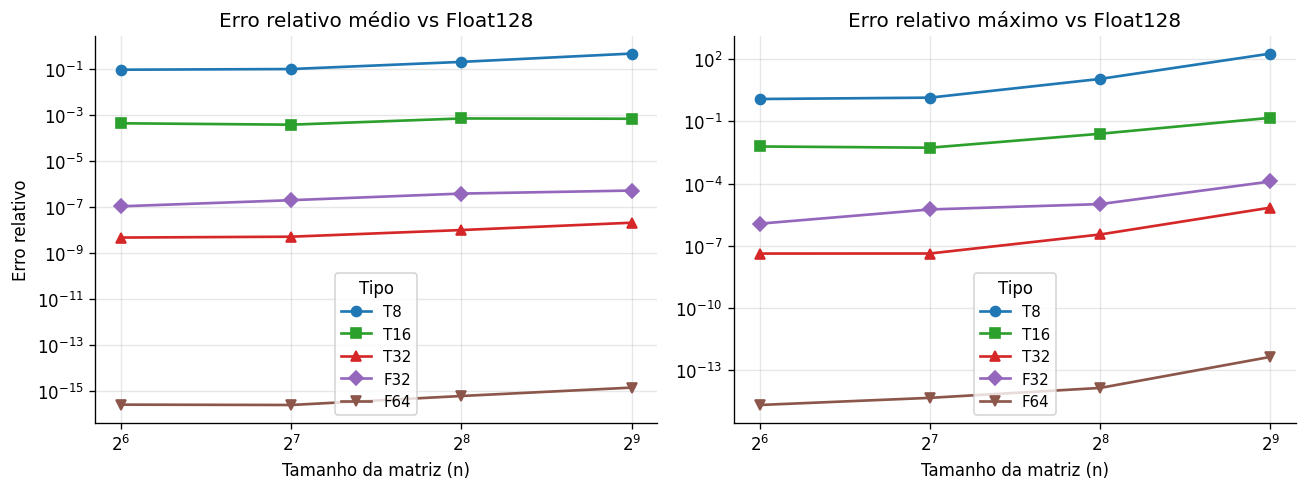

In [12]:
def plot_error_vs_size(df: pd.DataFrame, out_dir: Path) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    for ax, col, title in zip(
        axes,
        ["err_mean", "err_max"],
        ["Erro relativo médio vs Float128", "Erro relativo máximo vs Float128"],
    ):
        for be in TIPOS:
            sub = df[df["tipo"] == be].groupby("size")[col].mean()
            if sub.empty:
                continue
            ax.plot(sub.index, sub.values,
                    marker=MARKERS[be], color=COLORS[be], label=be, lw=1.6)
        ax.set_xscale("log", base=2)
        ax.set_yscale("log")
        ax.set_xlabel("Tamanho da matriz (n)")
        ax.set_title(title)
        ax.legend(title="Tipo", fontsize=9)
    axes[0].set_ylabel("Erro relativo")
    fig.tight_layout()
    fig.savefig(out_dir / "fig_err_vs_size.png")
    plt.show()
    plt.close(fig)

plot_error_vs_size(df, FIG_DIR)

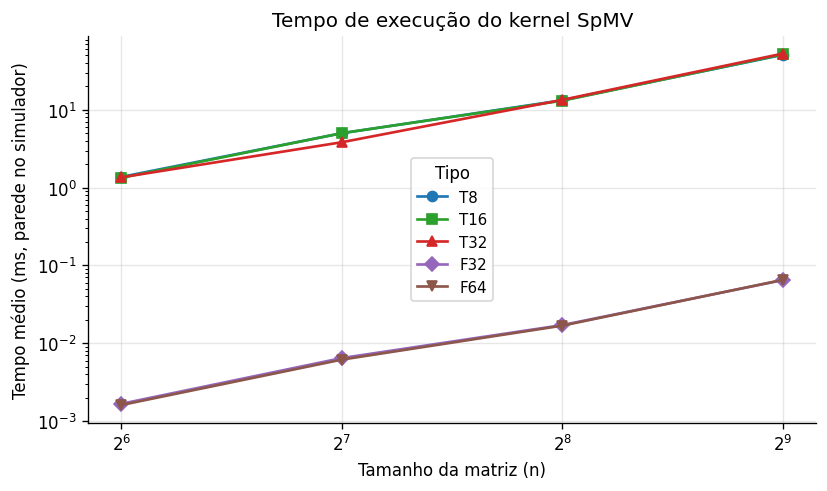

In [13]:
def plot_time_vs_size(df: pd.DataFrame, out_dir: Path) -> None:
    fig, ax = plt.subplots(figsize=(7, 4.2))
    for be in TIPOS:
        sub = df[df["tipo"] == be].groupby("size")["time_s"].mean() * 1e3
        if sub.empty:
            continue
        ax.plot(sub.index, sub.values,
                marker=MARKERS[be], color=COLORS[be], label=be, lw=1.6)
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xlabel("Tamanho da matriz (n)")
    ax.set_ylabel("Tempo médio (ms, parede no simulador)")
    ax.set_title("Tempo de execução do kernel SpMV")
    ax.legend(title="Tipo", fontsize=9)
    fig.tight_layout()
    fig.savefig(out_dir / "fig_time_vs_size.png")
    plt.show()
    plt.close(fig)

plot_time_vs_size(df, FIG_DIR)

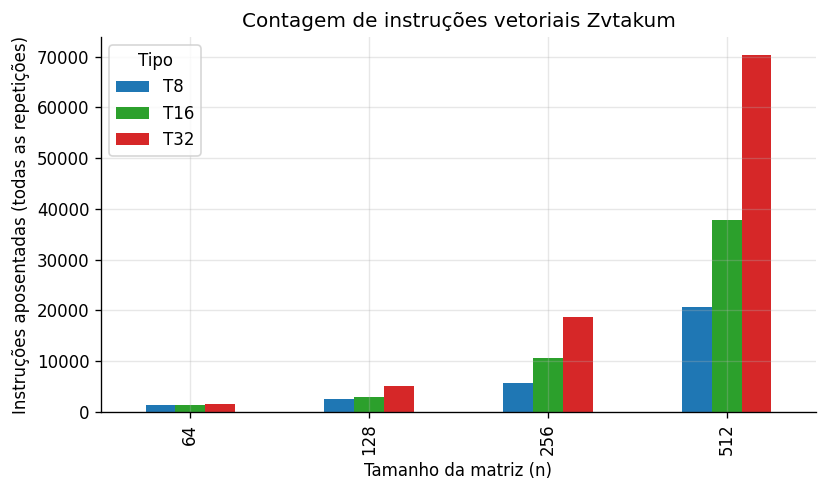

In [14]:
def plot_inst_retired(df: pd.DataFrame, out_dir: Path) -> None:
    sub = df[df["tipo"].isin(["T8", "T16", "T32"])]
    if sub.empty:
        return
    pivot = sub.pivot_table(
        index="size", columns="tipo",
        values="inst_retired", aggfunc="sum",
    ).reindex(columns=["T8", "T16", "T32"])
    fig, ax = plt.subplots(figsize=(7, 4.2))
    pivot.plot(kind="bar", ax=ax,
               color=[COLORS[c] for c in pivot.columns])
    ax.set_xlabel("Tamanho da matriz (n)")
    ax.set_ylabel("Instruções aposentadas (todas as repetições)")
    ax.set_title("Contagem de instruções vetoriais Zvtakum")
    ax.legend(title="Tipo")
    fig.tight_layout()
    fig.savefig(out_dir / "fig_inst_retired.png")
    plt.show()
    plt.close(fig)

plot_inst_retired(df, FIG_DIR)

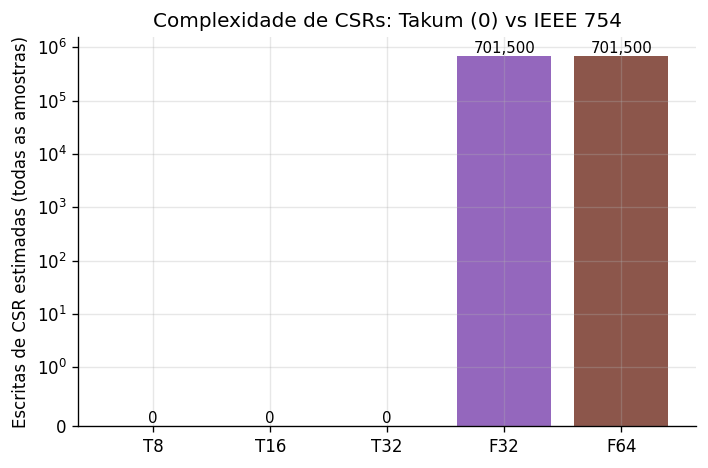

In [15]:
def plot_csr_writes(df: pd.DataFrame, out_dir: Path) -> None:
    agg = df.groupby("tipo")["csr_writes_est"].sum().reindex(TIPOS)
    fig, ax = plt.subplots(figsize=(6, 4))
    bars = ax.bar(agg.index, agg.values,
                  color=[COLORS[b] for b in agg.index])
    ax.set_ylabel("Escritas de CSR estimadas (todas as amostras)")
    ax.set_title("Complexidade de CSRs: Takum (0) vs IEEE 754")
    for bar, v in zip(bars, agg.values):
        ax.annotate(f"{int(v):,}", (bar.get_x() + bar.get_width() / 2, v),
                    ha="center", va="bottom", fontsize=9)
    ax.set_yscale("symlog", linthresh=1)
    fig.tight_layout()
    fig.savefig(out_dir / "fig_csr_writes.png")
    plt.show()
    plt.close(fig)

plot_csr_writes(df, FIG_DIR)

/tmp/ipykernel_1033/3995767101.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=TIPOS, patch_artist=True, widths=0.6)


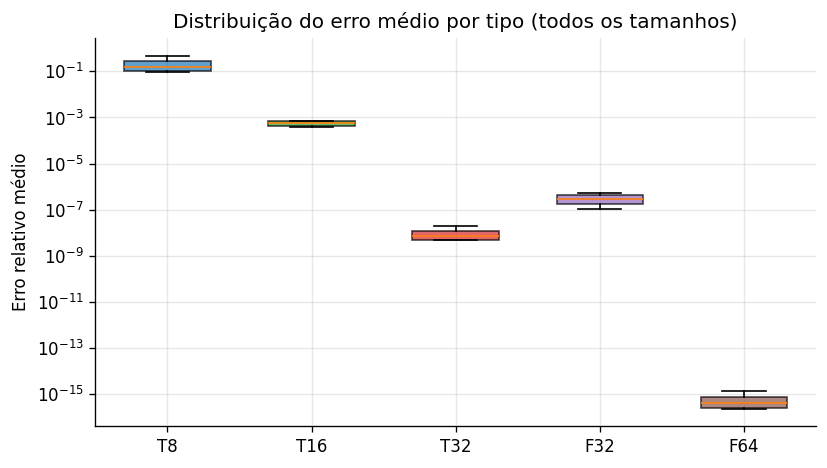

In [16]:
def plot_err_boxplot(df: pd.DataFrame, out_dir: Path) -> None:
    data = [df.loc[df["tipo"] == be, "err_mean"].dropna().values
            for be in TIPOS]
    fig, ax = plt.subplots(figsize=(7, 4))
    bp = ax.boxplot(data, labels=TIPOS, patch_artist=True, widths=0.6)
    for patch, be in zip(bp["boxes"], TIPOS):
        patch.set_facecolor(COLORS[be]); patch.set_alpha(0.7)
    ax.set_yscale("log")
    ax.set_ylabel("Erro relativo médio")
    ax.set_title("Distribuição do erro médio por tipo (todos os tamanhos)")
    fig.tight_layout()
    fig.savefig(out_dir / "fig_err_boxplot.png")
    plt.show()
    plt.close(fig)

plot_err_boxplot(df, FIG_DIR)

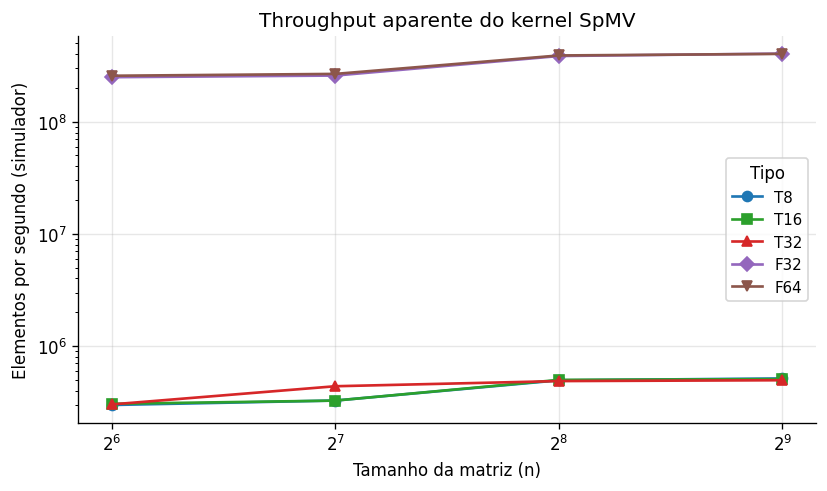

In [17]:
def plot_throughput(df: pd.DataFrame, out_dir: Path) -> None:
    fig, ax = plt.subplots(figsize=(7, 4.2))
    for be in TIPOS:
        sub = df[df["tipo"] == be].copy()
        if sub.empty:
            continue
        sub["elems"] = sub["size"].astype(float) ** 2 * (1 - 0.90)
        sub["thr"] = sub["elems"] / sub["time_s"].replace(0, np.nan)
        g = sub.groupby("size")["thr"].mean()
        ax.plot(g.index, g.values, marker=MARKERS[be],
                color=COLORS[be], label=be, lw=1.6)
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xlabel("Tamanho da matriz (n)")
    ax.set_ylabel("Elementos por segundo (simulador)")
    ax.set_title("Throughput aparente do kernel SpMV")
    ax.legend(title="Tipo", fontsize=9)
    fig.tight_layout()
    fig.savefig(out_dir / "fig_throughput.png")
    plt.show()
    plt.close(fig)

plot_throughput(df, FIG_DIR)

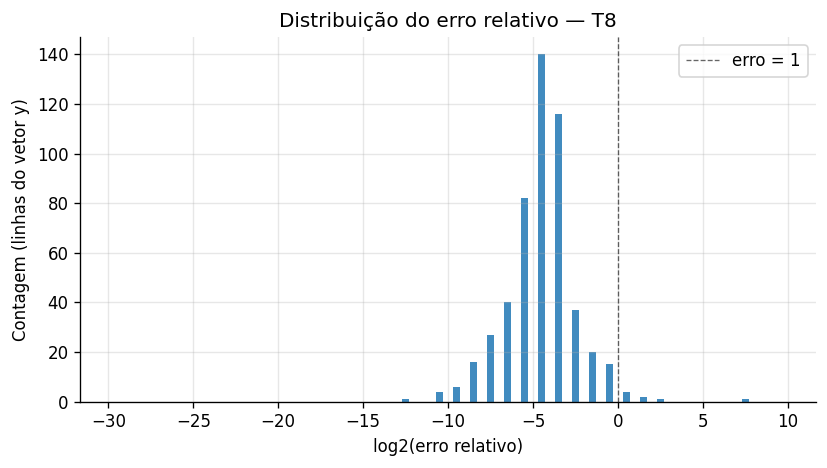

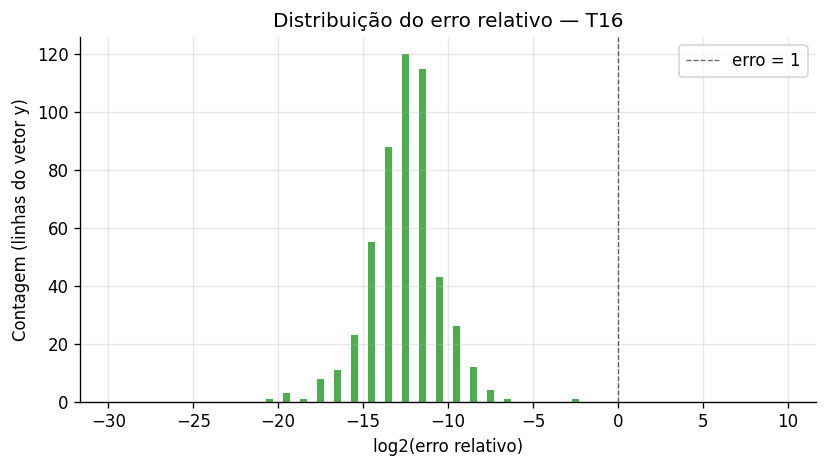

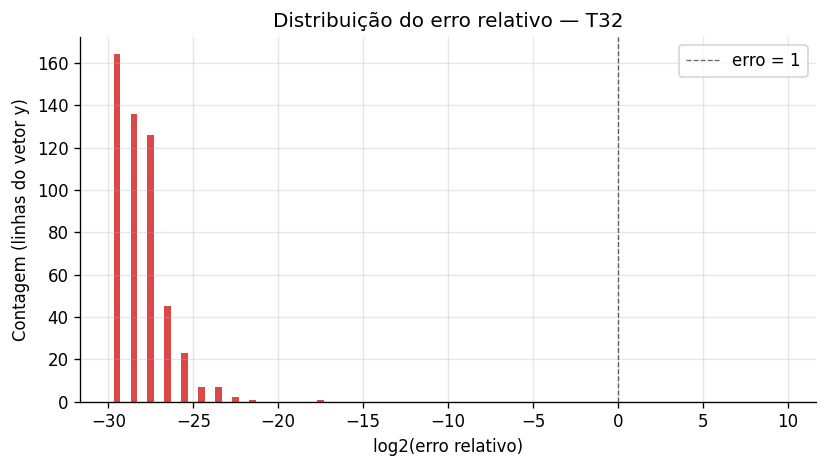

In [18]:
def plot_histograms(base_dir: Path, out_dir: Path) -> None:
    for be in ["T8", "T16", "T32"]:
        hist = load_hist(base_dir / f"benchmark_hist_{be}.csv")
        if hist is None:
            continue
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.bar(hist["log2_err_bucket"], hist["count"],
               width=0.4, color=COLORS[be], alpha=0.85)
        ax.set_xlabel("log2(erro relativo)")
        ax.set_ylabel("Contagem (linhas do vetor y)")
        ax.set_title(f"Distribuição do erro relativo — {be}")
        ax.axvline(0, color="k", ls="--", lw=0.8, alpha=0.6,
                   label="erro = 1")
        ax.legend()
        fig.tight_layout()
        fig.savefig(out_dir / f"fig_hist_{be}.png")
        plt.show()
        plt.close(fig)

plot_histograms(Path("."), FIG_DIR)